# TuCaserito — Credit Scoring end-to-end (bodegas)
**Hackathon BBVA 2026 — Equipo 7**
**Scope: IA / ML / analítica (25%) + Datos sintéticos y evidencia (15%)**

Este notebook construye un **score de salud financiera / crediticia** para bodegas, de punta a punta:
1. Simula un dataset sintético de miles de bodegas (1 fila por bodega, con historial agregado).
2. Calcula los 5 criterios pedidos por el equipo + variables adicionales pertinentes a bodegas peruanas.
3. Entrena **regresión logística** (simple, interpretable, poca data necesaria — ideal para MVP).
4. Evalúa con métricas de clasificación binaria (AUC, matriz de confusión, calibración).
5. Convierte la probabilidad del modelo en un **score 0-100** y dibuja el **velocímetro (aguja)** que se mostrará en el MVP móvil.

> Nota: dataset 100% sintético, no usa data real de BBVA (regla del reto).


In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Wedge, Circle

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 50)


## 1. Simulación del dataset (1 fila por bodega)

A diferencia del notebook de forecast (serie diaria), aquí cada bodega es **una fila** con variables agregadas de los últimos ~6 meses — así se entrena en segundos incluso con miles de bodegas.

### Criterios pedidos por el equipo
1. **Regularidad de ventas** — % de días con venta y variabilidad de las ventas
2. **Pago puntual a proveedores** — % de pagos a tiempo y mora acumulada
3. **% de ventas registradas** — qué tanto digitaliza su movimiento (vs. solo efectivo no registrado)
4. **% de fiado sobre ventas y su cobro** — cuánto fía y qué tan rápido recupera
5. **Antigüedad del negocio**

### Variables adicionales pertinentes a bodegas peruanas
- Rubro (taxonomía real de la tabla `rubros`: bodega/restaurante/taller/distribuidora) y n_trabajadores
  (reemplaza a "zona": en la BD real es texto libre sin categorías ni regla de mapeo, igual que en el
  notebook de forecast; n_trabajadores sí existe directo en `empresas.n_trabajadores`)
- Formalidad (tiene RUC / régimen tributario)
- Uso de billetera digital (Yape/Plin) — proxy de bancarización
- Ingreso mensual promedio (tamaño del negocio)
- N° de alertas de quiebre de stock (proxy de mala gestión de caja)


In [2]:
N_BODEGAS = 4000  # miles de bodegas, dataset liviano (1 fila c/u)

# rubro: taxonomía real de la tabla `rubros` del modelo de datos (antes: categorías inventadas
# sin equivalente en la BD). n_trabajadores reemplaza a "zona": existe directo en
# empresas.n_trabajadores, mientras que zona es texto libre sin regla de mapeo acordada.
rubros = rng.choice(["bodega", "restaurante", "taller", "distribuidora"], size=N_BODEGAS, p=[0.70, 0.15, 0.08, 0.07])
n_trabajadores = rng.choice([1, 2, 3, 4, 5], size=N_BODEGAS, p=[0.45, 0.25, 0.15, 0.10, 0.05])
tiene_ruc = rng.random(N_BODEGAS) < 0.55
usa_billetera_digital = rng.random(N_BODEGAS) < 0.40

antiguedad_meses = rng.integers(1, 200, size=N_BODEGAS)
ingreso_mensual_prom = rng.lognormal(mean=7.8, sigma=0.5, size=N_BODEGAS)  # soles/mes

# --- 1. Regularidad de ventas ---
pct_dias_con_venta = np.clip(rng.normal(0.85, 0.12, N_BODEGAS), 0.3, 1.0)
cv_ventas = np.clip(rng.normal(0.35, 0.15, N_BODEGAS), 0.05, 1.2)  # coef. de variación (menor = más regular)

# --- 2. Pago puntual a proveedores ---
pct_pagos_a_tiempo = np.clip(rng.normal(0.80, 0.18, N_BODEGAS), 0, 1)
dias_mora_promedio = np.clip(rng.exponential(5, N_BODEGAS) * (1 - pct_pagos_a_tiempo + 0.1), 0, 60)

# --- 3. Días desde el último registro (proxy de digitalización/regularidad de registro) ---
# pct_ventas_registradas NO es calculable con data real: la BD solo tiene lo que SI se
# registro, no existe un total de "ventas reales" para comparar. Se reemplaza por este proxy,
# que SI es derivable de produccion: MAX(fecha_hora) de transacciones por empresa, hoy - esa fecha.
escala_digital = np.where(usa_billetera_digital | tiene_ruc, 2.0, 6.0)
dias_desde_ultimo_registro = np.clip(rng.exponential(escala_digital), 0, 45)

# --- 4. % de fiado sobre ventas y su cobro ---
pct_fiado_sobre_ventas = np.clip(rng.normal(0.20, 0.12, N_BODEGAS), 0, 0.7)
pct_fiado_cobrado_a_tiempo = np.clip(rng.normal(0.70, 0.20, N_BODEGAS), 0, 1)

# --- 5. Antigüedad ya generada arriba ---

# --- Adicionales ---
n_alertas_quiebre_stock = rng.poisson(lam=np.clip(1.5 - pct_dias_con_venta, 0.1, None) * 4, size=N_BODEGAS)

bodegas = pd.DataFrame({
    "bodega_id": [f"BOD-{i:05d}" for i in range(N_BODEGAS)],
    "n_trabajadores": n_trabajadores,
    "rubro": rubros,
    "tiene_ruc": tiene_ruc.astype(int),
    "usa_billetera_digital": usa_billetera_digital.astype(int),
    "antiguedad_meses": antiguedad_meses,
    "ingreso_mensual_prom": ingreso_mensual_prom,
    "pct_dias_con_venta": pct_dias_con_venta,
    "cv_ventas": cv_ventas,
    "pct_pagos_a_tiempo": pct_pagos_a_tiempo,
    "dias_mora_promedio": dias_mora_promedio,
    "dias_desde_ultimo_registro": dias_desde_ultimo_registro,
    "pct_fiado_sobre_ventas": pct_fiado_sobre_ventas,
    "pct_fiado_cobrado_a_tiempo": pct_fiado_cobrado_a_tiempo,
    "n_alertas_quiebre_stock": n_alertas_quiebre_stock,
})
bodegas.head()


,bodega_id,n_trabajadores,rubro,tiene_ruc,usa_billetera_digital,antiguedad_meses,ingreso_mensual_prom,pct_dias_con_venta,cv_ventas,pct_pagos_a_tiempo,dias_mora_promedio,dias_desde_ultimo_registro,pct_fiado_sobre_ventas,pct_fiado_cobrado_a_tiempo,n_alertas_quiebre_stock
0,BOD-00000,3,restaurante,0,0,139,2589.862016,1.000000,0.282432,1.000000,0.966523,7.632187,0.233230,0.327254,4
1,BOD-00001,1,bodega,0,1,132,1466.797381,0.706100,0.229369,0.693350,0.334426,0.151583,0.165796,0.609109,6
2,BOD-00002,4,taller,1,1,182,6477.130939,0.753270,0.347470,0.577663,2.594521,0.123890,0.125430,0.741359,4
3,BOD-00003,1,bodega,1,0,73,6150.870302,0.763157,0.348892,0.742989,1.135358,1.997877,0.264707,0.748556,2
4,BOD-00004,2,bodega,0,1,151,865.289928,1.000000,0.516094,0.617602,0.632454,1.457800,0.162036,0.458644,2


### Variable objetivo: `buen_pagador`

Se simula una **probabilidad latente de buen comportamiento de pago** como combinación lineal de los 5 criterios (con pesos que reflejan su importancia relativa) + ruido, y se convierte en etiqueta binaria (1 = buen pagador / bajo riesgo, 0 = alto riesgo). Esto define un **ground truth sintético controlado**, necesario para poder evaluar el modelo (con data real no se tendría la "verdad" explícita, por eso se simula aquí).


In [3]:
antiguedad_norm = np.clip(bodegas["antiguedad_meses"] / 60, 0, 1)  # normaliza a ~5 años

# Escala 0.6 sobre los pesos + ruido std=1.0: calibrado para que el prior quede
# cerca de 50/50 (sin esto, casi todas las bodegas salian "buen pagador").
ESCALA = 1.5
logit_latente = (
    -5.93
    + ESCALA * (
        2.0 * bodegas["pct_dias_con_venta"]
        - 1.5 * bodegas["cv_ventas"]
        + 2.2 * bodegas["pct_pagos_a_tiempo"]
        - 0.04 * bodegas["dias_mora_promedio"]
        - 0.15 * bodegas["dias_desde_ultimo_registro"]
        - 1.3 * bodegas["pct_fiado_sobre_ventas"]
        + 1.4 * bodegas["pct_fiado_cobrado_a_tiempo"]
        + 1.1 * antiguedad_norm
        - 0.08 * bodegas["n_alertas_quiebre_stock"]
        + 0.3 * bodegas["tiene_ruc"]
    )
    + rng.normal(0, 0.4, N_BODEGAS)  # ruido: evita separabilidad perfecta
)

prob_buen_pagador = 1 / (1 + np.exp(-logit_latente))
bodegas["buen_pagador"] = (rng.random(N_BODEGAS) < prob_buen_pagador).astype(int)

print(bodegas["buen_pagador"].value_counts(normalize=True).round(3))


buen_pagador
1    0.503
0    0.497
Name: proportion, dtype: float64


### Supuestos y justificación de realismo

| Supuesto | Justificación |
|---|---|
| Pesos positivos en regularidad, puntualidad, registro, cobro de fiado y antigüedad | Son exactamente los 5 criterios definidos por el equipo como señales de buen comportamiento financiero |
| Peso negativo en `cv_ventas` y `dias_mora_promedio` | Mayor variabilidad de ventas y mora son señales de riesgo, consistente con literatura de credit scoring |
| `dias_desde_ultimo_registro` correlacionado con billetera digital y RUC | Negocios más formales/digitalizados registran más seguido; se usa este proxy medible en vez de pct_ventas_registradas, que no es calculable con data real (no hay ground truth de ventas totales para comparar) |
| Ruido gaussiano en el logit | Evita que el problema sea trivialmente separable — obliga a la regresión logística a aprender pesos, no memorizar una regla determinística |
| ~45-55% buen pagador esperado | Balance realista para un dataset de entrenamiento (ni trivialmente desbalanceado ni 50/50 perfecto) |

Documentado aquí para trazabilidad del entregable *Dataset sintético*.


## 2. Exportación del dataset sintético (entregable)


In [4]:
import os

EXPORT_DIR = "data_sintetica"
os.makedirs(EXPORT_DIR, exist_ok=True)
ruta = os.path.join(EXPORT_DIR, "bodegas_credit_scoring.csv")
bodegas.to_csv(ruta, index=False)
print(f"Dataset credit scoring: {ruta} -> {bodegas.shape[0]:,} filas, {bodegas.shape[1]} columnas")


Dataset credit scoring: data_sintetica\bodegas_credit_scoring.csv -> 4,000 filas, 16 columnas


## 3. Preparación y split (train/test estratificado)

A diferencia del forecast, aquí no hay fecha (es snapshot agregado por bodega), así que el split es aleatorio estratificado por la clase objetivo.


In [5]:
FEATURES_NUM = [
    "antiguedad_meses", "ingreso_mensual_prom",
    "pct_dias_con_venta", "cv_ventas",
    "pct_pagos_a_tiempo", "dias_mora_promedio",
    "dias_desde_ultimo_registro",
    "pct_fiado_sobre_ventas", "pct_fiado_cobrado_a_tiempo",
    "n_alertas_quiebre_stock",
    "n_trabajadores",
]
FEATURES_BIN = ["tiene_ruc", "usa_billetera_digital"]
FEATURES_CAT = ["rubro"]

X = pd.get_dummies(bodegas[FEATURES_NUM + FEATURES_BIN + FEATURES_CAT], columns=FEATURES_CAT, drop_first=True)
y = bodegas["buen_pagador"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,} | N features: {X.shape[1]}")


Train: 3,000 | Test: 1,000 | N features: 16


## 4. Entrenamiento — Regresión Logística

Se eligió regresión logística (vs. modelos más complejos) porque:
- **Poca data necesaria** para entrenar bien (miles de filas, no millones).
- **Interpretable**: cada coeficiente dice cuánto pesa cada criterio en el score — clave para explicarle al bodeguero *por qué* tiene tal puntaje, y para que el jurado vea la relación directa con los 5 criterios pedidos.
- **Output nativo en probabilidad** (0-1), que se traduce directo a un score 0-100 para el velocímetro del MVP.


In [6]:
modelo = LogisticRegression(max_iter=1000, random_state=SEED)
modelo.fit(X_train_scaled, y_train)

y_proba = modelo.predict_proba(X_test_scaled)[:, 1]
y_pred = modelo.predict(X_test_scaled)

auc = roc_auc_score(y_test, y_proba)
print(f"AUC: {auc:.3f}\n")
print(classification_report(y_test, y_pred, target_names=["alto_riesgo", "buen_pagador"]))


AUC: 0.764

              precision    recall  f1-score   support

 alto_riesgo       0.70      0.66      0.68       497
buen_pagador       0.68      0.72      0.70       503

    accuracy                           0.69      1000
   macro avg       0.69      0.69      0.69      1000
weighted avg       0.69      0.69      0.69      1000



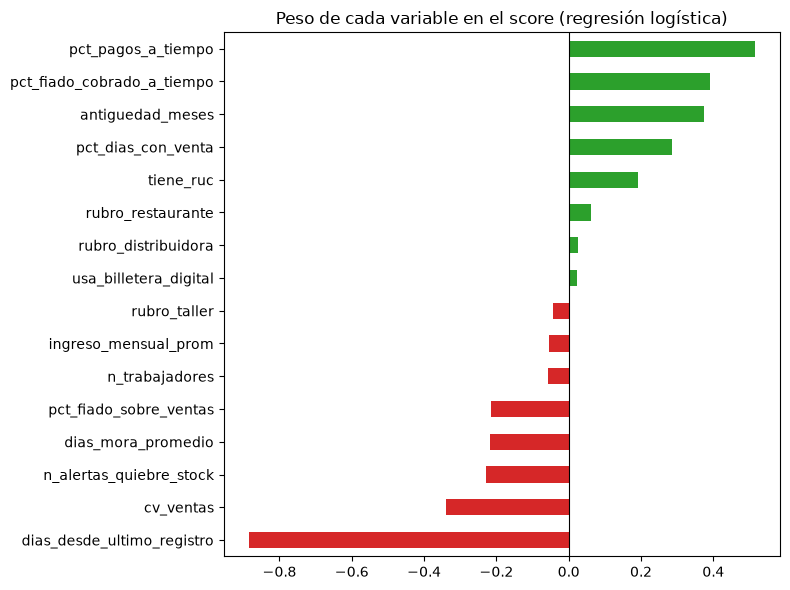

In [7]:
# Importancia de cada criterio (coeficientes estandarizados)
coef = pd.Series(modelo.coef_[0], index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#d62728" if c < 0 else "#2ca02c" for c in coef.values]
coef.plot.barh(ax=ax, color=colors)
ax.set_title("Peso de cada variable en el score (regresión logística)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


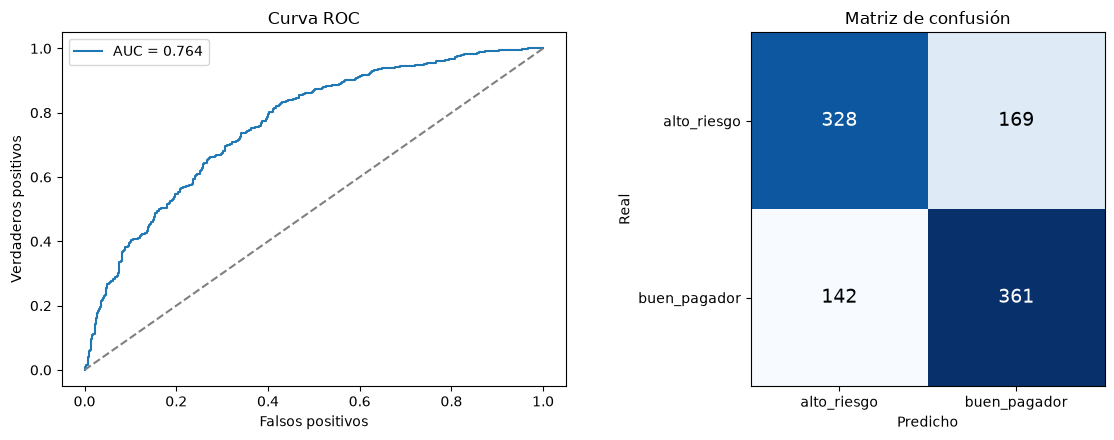

In [8]:
# Curva ROC y matriz de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, color="#1f77b4", label=f"AUC = {auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("Falsos positivos")
axes[0].set_ylabel("Verdaderos positivos")
axes[0].set_title("Curva ROC")
axes[0].legend()

cm = confusion_matrix(y_test, y_pred)
im = axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                      color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["alto_riesgo", "buen_pagador"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["alto_riesgo", "buen_pagador"])
axes[1].set_xlabel("Predicho"); axes[1].set_ylabel("Real")
axes[1].set_title("Matriz de confusión")
plt.tight_layout()
plt.show()


### 4.1 Exportación del modelo entrenado (para consumo posterior por el backend)

Se guarda el modelo (`LogisticRegression`) y el `StandardScaler` ajustado en `modelo/artifacts/credit_scoring/`, junto con un `metadata.json` que documenta el orden exacto de columnas tras el one-hot encoding (`pd.get_dummies`) y los umbrales del score — necesario para que el backend reconstruya el mismo preprocesamiento al scorear una bodega nueva.

In [9]:
import os
import json
import joblib

ARTIFACTS_DIR = os.path.join("artifacts", "credit_scoring")
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

joblib.dump(modelo, os.path.join(ARTIFACTS_DIR, "logreg_model.joblib"))
joblib.dump(scaler, os.path.join(ARTIFACTS_DIR, "scaler.joblib"))

metadata = {
    "tipo_modelo": "LogisticRegression (scikit-learn)",
    "columnas_en_orden": list(X.columns),
    "features_numericas": FEATURES_NUM,
    "features_binarias": FEATURES_BIN,
    "features_categoricas_originales": FEATURES_CAT,
    "categorias_rubro": sorted(bodegas["rubro"].unique().tolist()),
    "auc_test": round(float(auc), 4),
    "formula_score": "score = round(modelo.predict_proba(scaler.transform(X))[:, 1] * 100)",
    "rangos_categoria": {"Rojo (Poor)": "0-39", "Amarillo (Regular)": "40-69", "Verde (Good)": "70-100"},
    "reglas_acordadas": {
        "dias_desde_ultimo_registro": "Reemplaza a pct_ventas_registradas (no medible con data real). Se calcula como hoy - MAX(transacciones.fecha_hora) por empresa.",
        "pct_fiado_cobrado_a_tiempo": "Se usa SOLO como tasa agregada por empresa (promedio de fechas en cuaderno_fiado), nunca el campo individual cuaderno_fiado.pago_tardio, que queda reservado para evaluacion.",
        "n_alertas_quiebre_stock": "Proxy construido a partir de alertas.tipo_alerta = caida_ventas (no existe un tipo quiebre_stock en el enum; se podria agregar como mejora opcional, no es obligatorio).",
    },
    "integracion_score_salud": {
        "vista_features_propuesta": "v_empresas_credit_features (ver modelo_datos.dbml)",
        "clave_subindicador_propuesta": "riesgo_pago_ml",
        "formula": "round(modelo.predict_proba(scaler.transform(X))[:, 1] * 100)",
        "nota": "El score es inferencia de ML (requiere cargar logreg_model.joblib + scaler.joblib), no es un campo calculado via SQL. La vista solo resuelve las features de entrada; el backend debe correr el modelo y escribir el resultado dentro de score_salud.subindicadores. Clave y forma de combinarlo con otros subindicadores, a confirmar con el equipo.",
    },
    "notas": "Para scorear una bodega nueva: construir X con pd.get_dummies igual que aqui (mismas columnas_en_orden, rellenando con 0 las categorias ausentes), aplicar scaler.transform, luego modelo.predict_proba.",
}
with open(os.path.join(ARTIFACTS_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"Modelo y metadata exportados a {ARTIFACTS_DIR}/")
print(os.listdir(ARTIFACTS_DIR))

Modelo y metadata exportados a artifacts\credit_scoring/
['logreg_model.joblib', 'metadata.json', 'scaler.joblib']


## 5. De probabilidad a Score 0-100

La salida del modelo (`predict_proba`) es una probabilidad de "buen pagador". Se escala a un **score 0-100** (estilo FICO simplificado) para mostrarlo en el velocímetro del MVP:

```
score = round(probabilidad_buen_pagador * 100)
```

Rangos sugeridos para el velocímetro (igual al mockup de 3 colores):
- **0-40 → Rojo (Poor)**: alto riesgo, requiere acompañamiento financiero
- **40-70 → Amarillo (Regular)**: riesgo medio, oportunidad de mejora guiada por el app
- **70-100 → Verde (Good)**: bajo riesgo, elegible para productos financieros BBVA


In [10]:
def score_y_categoria(proba):
    score = round(proba * 100)
    if score < 40:
        categoria = "Rojo (Poor)"
    elif score < 70:
        categoria = "Amarillo (Regular)"
    else:
        categoria = "Verde (Good)"
    return score, categoria

bodegas_test = bodegas.loc[X_test.index].copy()
bodegas_test["proba_buen_pagador"] = y_proba
bodegas_test["score"], bodegas_test["categoria"] = zip(*bodegas_test["proba_buen_pagador"].map(score_y_categoria))

bodegas_test[["bodega_id", "antiguedad_meses", "pct_pagos_a_tiempo", "pct_fiado_sobre_ventas",
              "proba_buen_pagador", "score", "categoria"]].sort_values("score", ascending=False).head(10)


,bodega_id,antiguedad_meses,pct_pagos_a_tiempo,pct_fiado_sobre_ventas,proba_buen_pagador,score,categoria
1770,BOD-01770,178,1.000000,0.000000,0.980990,98,Verde (Good)
3541,BOD-03541,181,1.000000,0.216513,0.966357,97,Verde (Good)
3970,BOD-03970,144,0.898006,0.110816,0.950734,95,Verde (Good)
807,BOD-00807,112,1.000000,0.063027,0.946172,95,Verde (Good)
886,BOD-00886,76,1.000000,0.109323,0.953516,95,Verde (Good)
1243,BOD-01243,93,1.000000,0.336785,0.937124,94,Verde (Good)
2261,BOD-02261,187,1.000000,0.064177,0.932918,93,Verde (Good)
1881,BOD-01881,171,0.984670,0.151991,0.929830,93,Verde (Good)
24,BOD-00024,120,0.944506,0.305148,0.916585,92,Verde (Good)
969,BOD-00969,194,0.882038,0.019147,0.919556,92,Verde (Good)


## 6. Velocímetro (aguja) — igual al mockup del MVP

Función reutilizable que dibuja el velocímetro de 3 zonas (rojo/amarillo/verde) con la aguja apuntando al score del bodeguero, para integrarse directo a la pantalla de score del MVP móvil.


Bodega de prueba: BOD-00661 | score = 80 | Verde (Good)


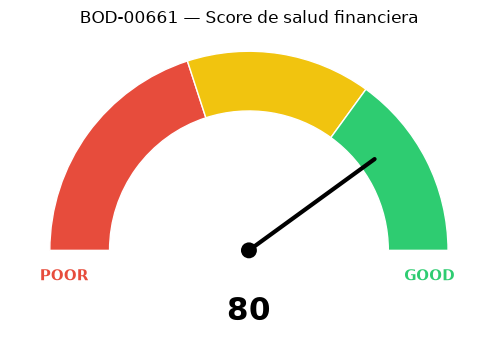

In [11]:
def dibujar_velocimetro(score, titulo="Score de salud financiera"):
    fig, ax = plt.subplots(figsize=(6, 3.5), subplot_kw={"aspect": "equal"})

    zonas_gauge = [
        (0, 40, "#e74c3c"),    # rojo - Poor
        (40, 70, "#f1c40f"),   # amarillo - Regular
        (70, 100, "#2ecc71"),  # verde - Good
    ]
    for ini, fin, color in zonas_gauge:
        ang_ini = 180 - (ini / 100) * 180
        ang_fin = 180 - (fin / 100) * 180
        ax.add_patch(Wedge((0, 0), 1, ang_fin, ang_ini, width=0.3, facecolor=color, edgecolor="white"))

    # Aguja
    angulo = np.radians(180 - (score / 100) * 180)
    x_aguja = 0.78 * np.cos(angulo)
    y_aguja = 0.78 * np.sin(angulo)
    ax.plot([0, x_aguja], [0, y_aguja], color="black", linewidth=3, solid_capstyle="round")
    ax.add_patch(Circle((0, 0), 0.04, facecolor="black"))

    ax.text(-1.05, -0.15, "POOR", color="#e74c3c", fontsize=11, fontweight="bold")
    ax.text(0.78, -0.15, "GOOD", color="#2ecc71", fontsize=11, fontweight="bold")
    ax.text(0, -0.35, f"{score}", ha="center", fontsize=22, fontweight="bold")
    ax.set_title(titulo, fontsize=12)

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-0.4, 1.1)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

# --- Prueba con un "sujeto" de ejemplo (igual al mockup) ---
sujeto = bodegas_test.sample(1, random_state=7).iloc[0]
print(f"Bodega de prueba: {sujeto['bodega_id']} | score = {sujeto['score']} | {sujeto['categoria']}")
dibujar_velocimetro(sujeto["score"], titulo=f"{sujeto['bodega_id']} — Score de salud financiera")


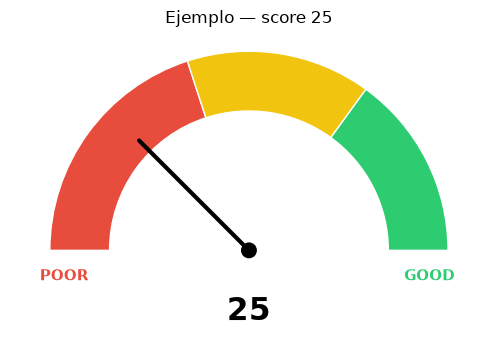

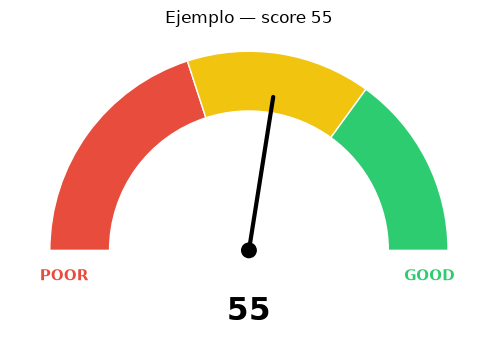

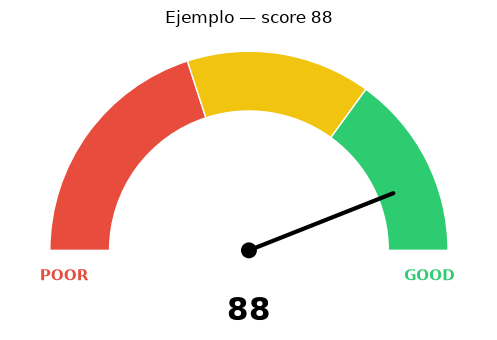

In [12]:
# Ejemplos en los 3 rangos, para validar visualmente que el velocímetro responde bien
for score_ejemplo in [25, 55, 88]:
    dibujar_velocimetro(score_ejemplo, titulo=f"Ejemplo — score {score_ejemplo}")


## 7. Resumen ejecutivo (para la presentación ante el jurado)

- **Dataset sintético**: 4,000 bodegas (snapshot agregado), con los 5 criterios pedidos por el equipo + variables de formalidad/digitalización propias del contexto peruano.
- **Modelo elegido**: Regresión logística — interpretable, poca data necesaria, output nativo en probabilidad.
- **Resultado**: ver AUC y matriz de confusión arriba; cada coeficiente es trazable a uno de los 5 criterios del reto.
- **Output para el MVP**: `score` (0-100) + `categoria` (Rojo/Amarillo/Verde), visualizado como velocímetro con aguja — igual al mockup compartido por el equipo.
- **Integración**: el campo `nivel_riesgo` definido en `contract.md` se mapea directo a las 3 categorías del velocímetro.
- **Replicabilidad**: pipeline reproducible con seed fijo; mismas columnas que se podrían obtener de `transacciones_venta`, `cuaderno_fiado` y `prestamos_proveedor` una vez el backend tenga data real.
